In [ ]:
!pip install pgmpy
!pip install hmmlearn

import matplotlib.pyplot as plt
import networkx as nx
from pgmpy.factors.discrete import TabularCPD
from pgmpy.inference import VariableElimination

# in versiunile noi clasa se numeste DiscreteBayesianNetwork, in cele vechi BayesianNetwork
try:
    from pgmpy.models import DiscreteBayesianNetwork as BN
except ImportError:
    from pgmpy.models import BayesianNetwork as BN

import numpy as np
from hmmlearn import hmm


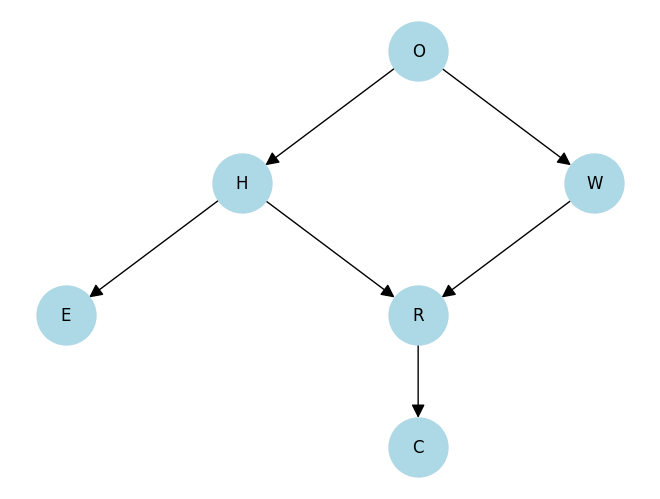

In [4]:
# 1

# ---------------- a) constructia retelei ----------------

# muchiile arata cine influenteaza pe cine (parinte -> copil)
model = BN([
    ("O", "H"),
    ("O", "W"),
    ("H", "R"),
    ("W", "R"),
    ("H", "E"),
    ("R", "C"),
])

# P(O): nu are parinti, deci avem o singura coloana
cpd_O = TabularCPD("O", 2, [[0.3], [0.7]],
                   state_names={"O": ["cold", "mild"]})

# P(H | O): fiecare coloana e o valoare a lui O (cold, mild), iar coloanele suma 1
# randul 0 = yes, randul 1 = no
cpd_H = TabularCPD("H", 2,
                   [[0.9, 0.2],
                    [0.1, 0.8]],
                   evidence=["O"], evidence_card=[2],
                   state_names={"H": ["yes", "no"], "O": ["cold", "mild"]})

# P(W | O)
cpd_W = TabularCPD("W", 2,
                   [[0.1, 0.6],
                    [0.9, 0.4]],
                   evidence=["O"], evidence_card=[2],
                   state_names={"W": ["yes", "no"], "O": ["cold", "mild"]})

# P(R | H, W): coloanele merg in ordinea (H=yes,W=yes), (yes,no), (no,yes), (no,no)
# randul 0 = warm, randul 1 = cool (= 1 - warm)
cpd_R = TabularCPD("R", 2,
                   [[0.6, 0.9, 0.3, 0.5],
                    [0.4, 0.1, 0.7, 0.5]],
                   evidence=["H", "W"], evidence_card=[2, 2],
                   state_names={"R": ["warm", "cool"],
                                "H": ["yes", "no"],
                                "W": ["yes", "no"]})

# P(E | H)
cpd_E = TabularCPD("E", 2,
                   [[0.8, 0.2],
                    [0.2, 0.8]],
                   evidence=["H"], evidence_card=[2],
                   state_names={"E": ["high", "low"], "H": ["yes", "no"]})

# P(C | R)
cpd_C = TabularCPD("C", 2,
                   [[0.85, 0.40],
                    [0.15, 0.60]],
                   evidence=["R"], evidence_card=[2],
                   state_names={"C": ["comfortable", "uncomfortable"],
                                "R": ["warm", "cool"]})

model.add_cpds(cpd_O, cpd_H, cpd_W, cpd_R, cpd_E, cpd_C)

# verifica daca structura si tabelele sunt corecte (suma pe coloane = 1 etc.)
assert model.check_model()

# desenam graful
pos = {
    "O": (1, 3), "H": (0, 2), "W": (2, 2),
    "R": (1, 1), "E": (-1, 1), "C": (1, 0),
}
nx.draw(model, pos, with_labels=True, node_size=1800,
        node_color="lightblue", arrowsize=20)
plt.savefig("graf_subiect1.png")
plt.show()

In [5]:
# ---------------- b) inferenta cu variable elimination ----------------

infer = VariableElimination(model)
ev = {"C": "comfortable"}  # evidenta data in enunt

# P(H = yes | C = comfortable)
q_h = infer.query(["H"], evidence=ev)
print("P(H | C=comfortable):")
print(q_h)  # valoarea cautata e cea de la H=yes

# P(E = high | C = comfortable)
q_e = infer.query(["E"], evidence=ev)
print("P(E | C=comfortable):")
print(q_e)  # valoarea cautata e cea de la E=high

# MAP pentru (H, W) | C = comfortable
# map_query intoarce doar asignarea cea mai probabila
map_res = infer.map_query(["H", "W"], evidence=ev)
print("MAP (H, W):", map_res)

# pentru a vedea si probabilitatea, calculam distributia comuna P(H, W | C)
# si luam combinatia cu valoarea maxima
q_hw = infer.query(["H", "W"], evidence=ev)
print(q_hw)


P(H | C=comfortable):
+--------+----------+
| H      |   phi(H) |
+========+==========+
| H(yes) |   0.4823 |
+--------+----------+
| H(no)  |   0.5177 |
+--------+----------+
P(E | C=comfortable):
+---------+----------+
| E       |   phi(E) |
+=========+==========+
| E(high) |   0.4894 |
+---------+----------+
| E(low)  |   0.5106 |
+---------+----------+


  0%|          | 0/2 [00:00<?, ?it/s]

  0%|          | 0/2 [00:00<?, ?it/s]

MAP (H, W): {'W': 'no', 'H': 'yes'}
+--------+--------+------------+
| H      | W      |   phi(H,W) |
+========+========+============+
| H(yes) | W(yes) |     0.1138 |
+--------+--------+------------+
| H(yes) | W(no)  |     0.3684 |
+--------+--------+------------+
| H(no)  | W(yes) |     0.2776 |
+--------+--------+------------+
| H(no)  | W(no)  |     0.2401 |
+--------+--------+------------+


In [6]:
# ---------------- c) independente (d-separare) ----------------

# W _|_ E | H ?
# drumul W <- O -> H -> E este blocat, pentru ca H (observat) e nod intermediar
# intr-un lant (O -> H -> E), iar conditionarea pe un astfel de nod blocheaza drumul.
# drumul W -> R <- H -> E este blocat, pentru ca R e coliziune (W -> R <- H)
# si nici R, nici descendentul lui C nu sunt observate; in plus H e observat.
# toate drumurile sunt blocate => W si E sunt independente conditionat de H (DA).
print("W _|_ E | H :", not model.is_dconnected("W", "E", observed=["H"]))

# O _|_ C | R ?
# drumurile O -> H -> R -> C si O -> W -> R -> C trec amandoua prin R,
# care e nod intermediar in lant (H -> R -> C, W -> R -> C).
# R fiind observat, ambele drumuri sunt blocate => O si C sunt independente dat R (DA).
# alte drumuri (de ex. prin E) nu ajung la C, deci nu conteaza.
print("O _|_ C | R :", not model.is_dconnected("O", "C", observed=["R"]))

W _|_ E | H : True
O _|_ C | R : True


In [7]:
# 2

# ---------------- a) definirea modelului ----------------

# stari hidden: 0 = walking, 1 = running, 2 = resting
states = ["W", "R", "S"]
# observatii: 0 = low, 1 = medium, 2 = high
obs_names = ["L", "M", "H"]

# probabilitati initiale P(stare la t=1)
start_p = np.array([0.4, 0.3, 0.3])

# matricea de tranzitie: linia i = starea curenta, coloana j = starea urmatoare
# fiecare linie are suma 1
trans_p = np.array([
    [0.6, 0.3, 0.1],   # din W
    [0.2, 0.7, 0.1],   # din R
    [0.3, 0.2, 0.5],   # din S
])

# matricea de emisie: linia i = starea, coloana k = observatia (L, M, H)
emit_p = np.array([
    [0.10, 0.70, 0.20],   # W
    [0.05, 0.25, 0.70],   # R
    [0.80, 0.15, 0.05],   # S
])

# CategoricalHMM e pentru observatii discrete (in versiunile vechi de hmmlearn
# se folosea MultinomialHMM in locul lui)
model = hmm.CategoricalHMM(n_components=3, random_state=0)
model.startprob_ = start_p
model.transmat_ = trans_p
model.emissionprob_ = emit_p

# secventa de observat: [medium, high, low] = [1, 2, 0]
# hmmlearn vrea observatiile ca o coloana (n_pasi, 1)
obs = np.array([[1], [2], [0]])

In [8]:
# ---------------- b) algoritmul forward ----------------

def forward(obs_seq, pi, A, B):
    # alpha[t, i] = P(observatiile pana la t, starea la t = i)
    T = len(obs_seq)
    alpha = np.zeros((T, len(pi)))
    # primul pas: probabilitatea initiala inmultita cu emisia
    alpha[0] = pi * B[:, obs_seq[0]]
    for t in range(1, T):
        # alpha[t-1] @ A aduna peste toate starile anterioare posibile
        alpha[t] = (alpha[t - 1] @ A) * B[:, obs_seq[t]]
    # probabilitatea secventei = suma peste starea finala
    return alpha[-1].sum()

p_forward = forward(obs.flatten(), start_p, trans_p, emit_p)
print("P(M, H, L) forward (manual):", p_forward)

# verificare cu hmmlearn: score da log-probabilitatea, deci aplicam exp
print("P(M, H, L) hmmlearn:", np.exp(model.score(obs)))

P(M, H, L) forward (manual): 0.021117249999999997
P(M, H, L) hmmlearn: 0.021117250000000008


In [9]:
# ---------------- c) algoritmul viterbi ----------------

# decode intoarce log-probabilitatea celui mai bun drum si drumul in sine
log_p, path = model.decode(obs, algorithm="viterbi")
print("cea mai probabila secventa de stari:", [states[i] for i in path])
print("probabilitatea drumului:", np.exp(log_p))

# de ce viterbi si nu enumerare exhaustiva?
# cu N stari si o secventa de lungime T, enumerarea verifica N^T drumuri
# (creste exponential). viterbi retine pentru fiecare stare doar cel mai bun
# drum pana la pasul curent, deci costa N^2 * T (creste liniar cu T).


cea mai probabila secventa de stari: ['W', 'R', 'S']
probabilitatea drumului: 0.004703999999999999


In [10]:
# ---------------- d) simulare cu 10000 de secvente ----------------

n_sim = 10000
target = [1, 2, 0]   # M, H, L
count = 0

for _ in range(n_sim):
    # sample(3) genereaza 3 observatii (X) si starile ascunse folosite (Z)
    X, Z = model.sample(3)
    if X.flatten().tolist() == target:
        count += 1

p_emp = count / n_sim
print("probabilitate empirica:", p_emp)
print("probabilitate exacta (forward):", p_forward)
print("diferenta:", abs(p_emp - p_forward))
# diferenta mica e normala: estimarea e aleatoare si se apropie de valoarea
# exacta pe masura ce cresc numarul de simulari

probabilitate empirica: 0.0
probabilitate exacta (forward): 0.021117249999999997
diferenta: 0.021117249999999997
